In [ ]:

import random
import copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    classification_report, confusion_matrix
)


c:\Btech\SEM5\cuda\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:

# --------------------------------------------------
# SETTINGS
# --------------------------------------------------
SEED = 42
BATCH_SIZE = 16
NUM_WORKERS = 0

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# Dataset folder: Train/Person1..., Validation/Person8, Test/Person9
ROOT_DIR = Path(r"C:\Btech\SEM5\cuda\DL\Dataset")
TRAIN_DIR = ROOT_DIR / "Train"
VAL_DIR = ROOT_DIR / "Validation"
TEST_DIR = ROOT_DIR / "Test"

assert TRAIN_DIR.exists(), f"Missing folder: {TRAIN_DIR}"
assert VAL_DIR.exists(), f"Missing folder: {VAL_DIR}"
assert TEST_DIR.exists(), f"Missing folder: {TEST_DIR}"

# Put the existing checkpoint beside this notebook
CHECKPOINT_PATH = Path("best_personwise_custom_cnn.pth")
NEW_CHECKPOINT_PATH = Path("best_personwise_finetuned.pth")

assert CHECKPOINT_PATH.exists(), (
    f"Checkpoint not found: {CHECKPOINT_PATH.resolve()}\n"
    "Copy best_personwise_custom_cnn.pth beside this notebook."
)

CLASSES = ["Distraction", "Drinking", "Normal", "Phone", "Sleeping"]
CLASS_TO_IDX = {name: idx for idx, name in enumerate(CLASSES)}
IMAGE_EXTENSIONS = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}

def build_dataframe(split_path):
    rows = []

    for person_folder in sorted(p for p in split_path.iterdir() if p.is_dir()):
        for class_name in CLASSES:
            class_folder = person_folder / class_name

            if not class_folder.exists():
                continue

            for image_path in class_folder.iterdir():
                if image_path.suffix.lower() in IMAGE_EXTENSIONS:
                    rows.append({
                        "path": str(image_path),
                        "person": person_folder.name,
                        "class": class_name,
                        "label": CLASS_TO_IDX[class_name]
                    })

    return pd.DataFrame(rows)

train_df = build_dataframe(TRAIN_DIR)
val_df = build_dataframe(VAL_DIR)
test_df = build_dataframe(TEST_DIR)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Test images:", len(test_df))

print("Training people:", sorted(train_df["person"].unique()))
print("Validation people:", sorted(val_df["person"].unique()))
print("Test people:", sorted(test_df["person"].unique()))

# Confirm that the person-wise split has not changed
assert set(train_df["person"]) == {f"Person{i}" for i in range(1, 8)}
assert set(val_df["person"]) == {"Person8"}
assert set(test_df["person"]) == {"Person9"}

assert set(train_df["person"]).isdisjoint(set(val_df["person"]))
assert set(train_df["person"]).isdisjoint(set(test_df["person"]))
assert set(val_df["person"]).isdisjoint(set(test_df["person"]))

print("Person-wise hold-out verified!")

# Use the same transforms as the original experiment
train_transform = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=8),
    transforms.RandomAffine(
        degrees=0, translate=(0.03, 0.03), scale=(0.95, 1.05)
    ),
    transforms.ColorJitter(
        brightness=0.20, contrast=0.20, saturation=0.15, hue=0.03
    ),
    transforms.RandomApply([
        transforms.GaussianBlur(kernel_size=3)
    ], p=0.20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class DriverDataset(Dataset):
    def __init__(self, dataframe, transform):
        self.df = dataframe.reset_index(drop=True)
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, index):
        row = self.df.iloc[index]
        with Image.open(row["path"]) as img:
            image = img.convert("RGB")
            image = self.transform(image)
        return image, int(row["label"])

train_dataset = DriverDataset(train_df, train_transform)
val_dataset = DriverDataset(val_df, test_transform)
test_dataset = DriverDataset(test_df, test_transform)

train_loader = DataLoader(
    train_dataset, batch_size=BATCH_SIZE, shuffle=True,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)
val_loader = DataLoader(
    val_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    test_dataset, batch_size=BATCH_SIZE, shuffle=False,
    num_workers=NUM_WORKERS, pin_memory=torch.cuda.is_available()
)

weights = compute_class_weight(
    class_weight="balanced",
    classes=np.arange(len(CLASSES)),
    y=train_df["label"].to_numpy()
)
class_weights = torch.tensor(weights, dtype=torch.float32, device=DEVICE)

print("Class weights:", dict(zip(CLASSES, weights.round(3))))
print("Loaders ready.")


Device: cuda
GPU: NVIDIA GeForce RTX 4060 Laptop GPU
Training images: 25779
Validation images: 3548
Test images: 3565
Training people: ['Person1', 'Person2', 'Person3', 'Person4', 'Person5', 'Person6', 'Person7']
Validation people: ['Person8']
Test people: ['Person9']
Person-wise hold-out verified!
Class weights: {'Distraction': np.float64(1.066), 'Drinking': np.float64(0.899), 'Normal': np.float64(1.053), 'Phone': np.float64(0.967), 'Sleeping': np.float64(1.036)}
Loaders ready.


In [3]:

class CustomCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        self.features = nn.Sequential(
            nn.Conv2d(3, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(128, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            nn.Conv2d(256, 512, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(512),
            nn.ReLU(inplace=True),
            nn.AdaptiveAvgPool2d((1, 1))
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Dropout(0.60),
            nn.Linear(512, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.40),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)

model = CustomCNN(num_classes=len(CLASSES)).to(DEVICE)

saved_weights = torch.load(
    CHECKPOINT_PATH,
    map_location=DEVICE,
    weights_only=True
)
model.load_state_dict(saved_weights)

print("Original person-wise model loaded successfully!")
print("Starting fine-tuning from the learned weights.")


Original person-wise model loaded successfully!
Starting fine-tuning from the learned weights.


In [4]:

# --------------------------------------------------
# FINE-TUNING SETTINGS
# --------------------------------------------------
FINE_TUNE_EPOCHS = 10
LEARNING_RATE = 1e-5
EARLY_STOPPING_PATIENCE = 4

criterion = nn.CrossEntropyLoss(
    weight=class_weights,
    label_smoothing=0.05
)

# Fresh optimizer: model weights are loaded, optimizer state is not.
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=2,
    threshold=1e-3,
    min_lr=1e-7
)

scaler = torch.amp.GradScaler(
    "cuda", enabled=(DEVICE.type == "cuda")
)

def evaluate_validation():
    model.eval()
    all_true, all_pred = [], []
    total_loss = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)

            with torch.amp.autocast(
                device_type=DEVICE.type,
                enabled=(DEVICE.type == "cuda")
            ):
                outputs = model(images)
                loss = criterion(outputs, labels)

            total_loss += loss.item()
            all_true.extend(labels.cpu().numpy())
            all_pred.extend(outputs.argmax(1).cpu().numpy())

    return (
        total_loss / len(val_loader),
        accuracy_score(all_true, all_pred),
        f1_score(all_true, all_pred, average="macro", zero_division=0)
    )

# Establish the starting validation score using the loaded model
start_val_loss, start_val_acc, best_val_f1 = evaluate_validation()

print(f"Starting validation accuracy: {start_val_acc:.4f}")
print(f"Starting validation macro F1: {best_val_f1:.4f}")

# Save a separate copy so the original checkpoint remains untouched
best_state = copy.deepcopy(model.state_dict())
torch.save(best_state, NEW_CHECKPOINT_PATH)

history = {
    "train_loss": [],
    "val_loss": [],
    "train_acc": [],
    "val_acc": [],
    "train_f1": [],
    "val_f1": []
}

no_improvement = 0

for epoch in range(FINE_TUNE_EPOCHS):
    print(f"\nFine-tuning epoch {epoch + 1}/{FINE_TUNE_EPOCHS}")
    model.train()

    running_loss = 0.0
    train_true, train_pred = [], []

    for images, labels in tqdm(train_loader):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = model(images)
            loss = criterion(outputs, labels)

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)

        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        scaler.step(optimizer)
        scaler.update()

        running_loss += loss.item()
        train_true.extend(labels.cpu().numpy())
        train_pred.extend(outputs.argmax(1).detach().cpu().numpy())

    train_loss = running_loss / len(train_loader)
    train_acc = accuracy_score(train_true, train_pred)
    train_f1 = f1_score(
        train_true, train_pred, average="macro", zero_division=0
    )

    val_loss, val_acc, val_f1 = evaluate_validation()
    scheduler.step(val_f1)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    history["train_acc"].append(train_acc)
    history["val_acc"].append(val_acc)
    history["train_f1"].append(train_f1)
    history["val_f1"].append(val_f1)

    improved = val_f1 > best_val_f1

    if improved:
        best_val_f1 = val_f1
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, NEW_CHECKPOINT_PATH)
        no_improvement = 0
        status = "Improved validation macro F1 — checkpoint saved"
    else:
        no_improvement += 1
        status = f"No improvement: {no_improvement}/{EARLY_STOPPING_PATIENCE}"

    current_lr = optimizer.param_groups[0]["lr"]

    print(
        f"Train loss: {train_loss:.4f} | "
        f"Train accuracy: {train_acc:.4f} | "
        f"Train macro F1: {train_f1:.4f}"
    )
    print(
        f"Val loss: {val_loss:.4f} | "
        f"Val accuracy: {val_acc:.4f} | "
        f"Val macro F1: {val_f1:.4f}"
    )
    print(f"Learning rate: {current_lr:.2e}")
    print(status)

    if no_improvement >= EARLY_STOPPING_PATIENCE:
        print("Early stopping: validation macro F1 is not improving.")
        break

# Restore the best checkpoint from this fine-tuning experiment
model.load_state_dict(
    torch.load(NEW_CHECKPOINT_PATH, map_location=DEVICE, weights_only=True)
)
model.eval()

print("\nFine-tuning completed.")
print(f"Best validation macro F1: {best_val_f1:.4f}")
print(f"New checkpoint saved at: {NEW_CHECKPOINT_PATH.resolve()}")


Starting validation accuracy: 0.6077
Starting validation macro F1: 0.5983

Fine-tuning epoch 1/10


100%|██████████| 1612/1612 [15:26<00:00,  1.74it/s]


Train loss: 0.6017 | Train accuracy: 0.8417 | Train macro F1: 0.8415
Val loss: 1.2522 | Val accuracy: 0.5645 | Val macro F1: 0.5632
Learning rate: 1.00e-05
No improvement: 1/4

Fine-tuning epoch 2/10


100%|██████████| 1612/1612 [13:55<00:00,  1.93it/s]


Train loss: 0.5973 | Train accuracy: 0.8441 | Train macro F1: 0.8437
Val loss: 1.2014 | Val accuracy: 0.5538 | Val macro F1: 0.5232
Learning rate: 1.00e-05
No improvement: 2/4

Fine-tuning epoch 3/10


100%|██████████| 1612/1612 [13:00<00:00,  2.06it/s]


... (7 outputs left out)

100%|██████████| 1612/1612 [13:17<00:00,  2.02it/s]


Train loss: 0.5813 | Train accuracy: 0.8519 | Train macro F1: 0.8518
Val loss: 1.4552 | Val accuracy: 0.4913 | Val macro F1: 0.4304
Learning rate: 5.00e-06
No improvement: 3/4

Fine-tuning epoch 8/10


100%|██████████| 1612/1612 [13:30<00:00,  1.99it/s]


Train loss: 0.5706 | Train accuracy: 0.8569 | Train macro F1: 0.8566
Val loss: 1.3628 | Val accuracy: 0.5397 | Val macro F1: 0.5303
Learning rate: 5.00e-06
No improvement: 4/4
Early stopping: validation macro F1 is not improving.

Fine-tuning completed.
Best validation macro F1: 0.6063
New checkpoint saved at: C:\Btech\SEM5\cuda\DL\best_personwise_finetuned.pth



FINE-TUNED PERSON-WISE TEST RESULTS
Accuracy:  44.82%
Precision: 55.91%
Recall:    45.17%
Macro F1:  40.74%

CLASSIFICATION REPORT
              precision    recall  f1-score   support

 Distraction     0.5090    0.9784    0.6696       696
    Drinking     0.9895    0.1464    0.2551       642
      Normal     0.3526    0.3794    0.3655       709
       Phone     0.5955    0.2247    0.3262       819
    Sleeping     0.3491    0.5293    0.4207       699

    accuracy                         0.4482      3565
   macro avg     0.5591    0.4517    0.4074      3565
weighted avg     0.5529    0.4482    0.4068      3565



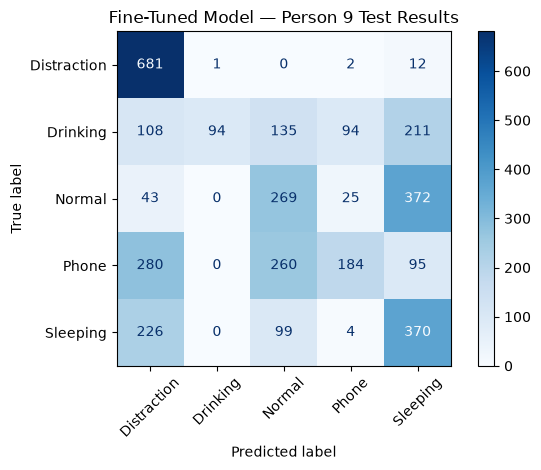

In [5]:

import torch
import numpy as np
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

# Load the best fine-tuned checkpoint
model.load_state_dict(
    torch.load(
        "best_personwise_finetuned.pth",
        map_location=DEVICE,
        weights_only=True
    )
)
model.eval()

test_true = []
test_pred = []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE, non_blocking=True)

        with torch.amp.autocast(
            device_type=DEVICE.type,
            enabled=(DEVICE.type == "cuda")
        ):
            outputs = model(images)

        predictions = outputs.argmax(dim=1)

        test_true.extend(labels.numpy())
        test_pred.extend(predictions.cpu().numpy())

print("\nFINE-TUNED PERSON-WISE TEST RESULTS")
print(f"Accuracy:  {accuracy_score(test_true, test_pred) * 100:.2f}%")
print(f"Precision: {precision_score(test_true, test_pred, average='macro', zero_division=0) * 100:.2f}%")
print(f"Recall:    {recall_score(test_true, test_pred, average='macro', zero_division=0) * 100:.2f}%")
print(f"Macro F1:  {f1_score(test_true, test_pred, average='macro', zero_division=0) * 100:.2f}%")

print("\nCLASSIFICATION REPORT")
print(classification_report(
    test_true,
    test_pred,
    labels=list(range(len(CLASSES))),
    target_names=CLASSES,
    digits=4,
    zero_division=0
))

cm = confusion_matrix(
    test_true,
    test_pred,
    labels=list(range(len(CLASSES)))
)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=CLASSES
)
disp.plot(cmap="Blues", values_format="d")
plt.title("Fine-Tuned Model — Person 9 Test Results")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(
    "personwise_finetuned_test_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()
